# Stochastic gradient descent: geometry, noise, and cost

Fred J. Hickernell · MATH 565, Fall 2026

Companion to [Selected Topics: Stochastic Gradient Descent](https://fjhickernell.github.io/MATH565Fall2026/slides/05-selected-topics.html#stochastic-gradient-descent-section).

Why did classical optimization warn us about gradient descent on the **banana function**, while machine learning often uses stochastic gradient methods? These are different questions:

- **Conditioning** controls how hard it is to move through the landscape.
- **Data access and required accuracy** control how much it is worth spending on a gradient.

High dimension does not make a narrow valley easier. A large dataset can make sampled gradients useful even with few parameters. Curvature-aware methods remain useful.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fjhickernell/MATH565Fall2026/blob/main/notebooks/performance/StochasticGradientDescent.ipynb)

Run All with the course `qmcpy` kernel. Change the parameter cell and rerun from the beginning. There is no downloaded dataset and no optional machine learning framework.

1. **Geometry:** Rosenbrock with backtracking GD and BFGS; then vary conditioning separately from dimension
2. **Monte Carlo gradients:** four component losses, mini-batch variance, and a solvable noise-floor experiment
3. **Cost:** regularized logistic regression, equal gradient-work budgets, and measured elapsed time

Consolidates the useful Rosenbrock and logistic-regression material from the Fall 2025 gradient notebooks. Random component indices and synthetic data use QMCPy IID sampling. All SGD batches are sampled **with replacement**.

In [1]:
from pathlib import Path
import subprocess
import sys
import time

NOTEBOOK_START_TIME = time.perf_counter()

colab = "google.colab" in sys.modules
if colab:
    print("Setting up this course's recorded classlib and QMCPy; this may take several minutes …")
    course_checkout = Path("/content/MATH565Fall2026")
    if not course_checkout.exists():
        subprocess.run(
            [
                "git", "clone", "--quiet", "--depth", "1",
                "https://github.com/fjhickernell/MATH565Fall2026.git",
                str(course_checkout),
            ],
            check=True,
        )
    subprocess.run(
        [
            "git", "-C", str(course_checkout),
            "-c", "submodule.classlib.url=https://github.com/fjhickernell/HickernellAcademicLib.git",
            "-c", "submodule.qmcpy.url=https://github.com/QMCSoftware/qmcpy.git",
            "submodule", "update", "--init", "classlib", "qmcpy",
        ],
        check=True,
    )
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install", "-q",
            str(course_checkout / "classlib"),
            str(course_checkout / "qmcpy"),
        ],
        check=True,
    )
    print("Colab setup complete.")
    print("For faster repeated work, use the local `qmcpy` environment.")

In [2]:
search_start = course_checkout if colab else Path.cwd().resolve()
course_root = next((p for p in [search_start, *search_start.parents]
                    if (p / 'course-metadata.yml').is_file()
                    and (p / 'qmcpy/qmcpy').is_dir()), None)
if course_root is None:
    raise RuntimeError('Run from the course checkout or use the Colab setup.')
for folder in ['classlib', 'qmcpy']:
    sys.path.insert(0, str(course_root / folder))

import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, rosen, rosen_der, rosen_hess
from scipy.special import expit
from IPython.display import display, Markdown
import qmcpy as qp
import classlib as cl

%matplotlib inline
cl.nbviz.init(use_tex=False)
pd.options.display.float_format = lambda x: f'{x:.6g}'
BLUE, GOLD, GREEN, RED = '#1f5a91', '#b77d17', '#398879', '#a93c42'

# Change these, then Run All. N and M are independent controls.
SEED = 5651105
N = 16384                    # Observations, indexed 0,...,N-1
M = 20                       # Parameters, including an intercept
REGULARIZATION = 0.02         # Applies to every parameter, including the intercept
BUDGET_PASSES = 12            # Exactly N * BUDGET_PASSES gradient contributions per run
BATCH_SIZE = 64
TIMING_REPEATS = 3            # Independent SGD streams; timing ranges are not confidence intervals
GD_BANANA_STEPS = 500
NOISE_STEPS, NOISE_REPEATS = 600, 256
assert N >= 64 and M >= 2 and REGULARIZATION > 0
assert BUDGET_PASSES >= 1 and 1 <= BATCH_SIZE <= N and TIMING_REPEATS >= 1
print(f'{platform.node()}: {platform.machine()}, {platform.platform()}')
print(f'Python {platform.python_version()}, NumPy {np.__version__}, QMCPy {qp.__version__}')
print('Timings describe this machine and this implementation; rerun before presenting.')

Freds-M3-MBP: arm64, macOS-27.0.1-arm64-arm-64bit-Mach-O
Python 3.13.13, NumPy 2.4.6, QMCPy 2.4
Timings describe this machine and this implementation; rerun before presenting.


## 1. The banana function is still difficult

The two-dimensional Rosenbrock objective is
\begin{gather*}
R(\boldsymbol\theta)=(1-\theta_1)^2+100(\theta_2-\theta_1^2)^2,
\qquad \boldsymbol\theta_*=(1,1)^\top,\\
\nabla R(\boldsymbol\theta)=
\begin{bmatrix}2(\theta_1-1)-400\theta_1(\theta_2-\theta_1^2)\\200(\theta_2-\theta_1^2)\end{bmatrix}.
\end{gather*}

A narrow curved valley makes the steepest local direction a poor guide to a long step. Compare two methods:

- **GD + backtracking** moves in the negative-gradient direction. Armijo backtracking starts with step size 1, tries the proposed endpoint, and halves the step size until the loss decreases sufficiently. It adjusts the step length, but not the direction; slow progress can persist despite this adaptive step size.
- **BFGS** builds an inverse-Hessian approximation from successive steps and gradients to adjust both the direction and scale of a step. It uses a line search but does not evaluate the exact Hessian.

The green star marks the minimizer $(1,1)$. Lines connect successive accepted iterates: the long blue segment is one GD update, not a continuous downhill trajectory. Backtracking checks its endpoint, so the connecting line can cross higher contours even though the endpoint lowers the loss. A separate close-up shows the much smaller later GD steps moving back and forth across the valley while making slow progress toward the minimizer.

The plots count **accepted updates**, which are not equal work. The table separately counts objective and gradient evaluations, including GD's rejected line-search trials. Rosenbrock is a deterministic geometry example: adding arbitrary noise to its gradient would not demonstrate a saving in data access.

Hessian eigenvalues at the minimizer: [3.99360767e-01 1.00160064e+03]
Local condition number: 2508.0


,Method,Accepted updates,Objective evaluations,Gradient evaluations,Final objective
0,GD + backtracking,500,4905,500,0.00191572
1,BFGS,34,41,41,4.35095e-25


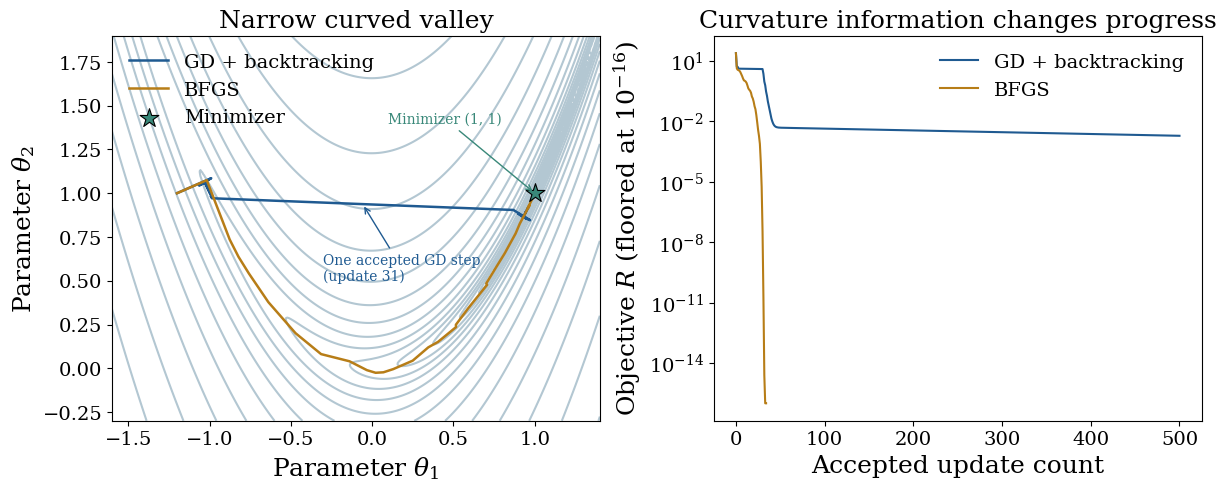

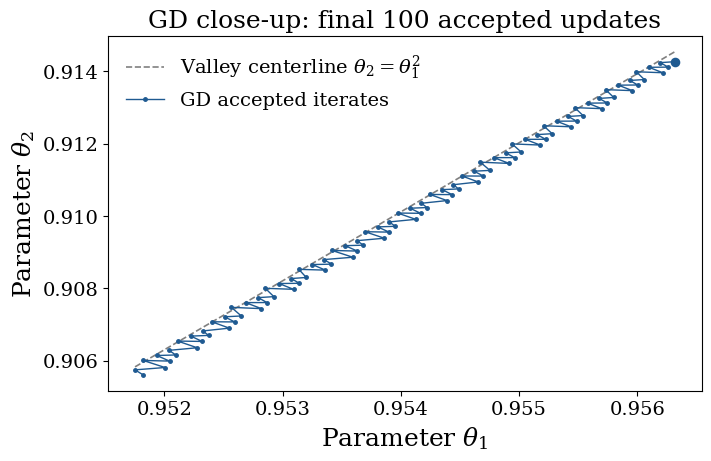

In [3]:
def banana_gd(start, steps):
    theta = np.array(start, dtype=float)
    path = [theta.copy()]
    values = [rosen(theta)]
    nfun, ngrad = 1, 0
    for _ in range(steps):
        g = rosen_der(theta)
        ngrad += 1
        eta = 1.0
        candidate_value = rosen(theta - eta*g)
        nfun += 1
        while candidate_value > values[-1] - 1e-4*eta*(g@g):
            eta *= 0.5
            candidate_value = rosen(theta - eta*g)
            nfun += 1
        theta -= eta*g
        path.append(theta.copy())
        values.append(candidate_value)
    return np.array(path), np.array(values), nfun, ngrad

banana_start = np.array([-1.2, 1.0])
gd_path, gd_values, gd_nfun, gd_ngrad = banana_gd(banana_start, GD_BANANA_STEPS)
bfgs_path = [banana_start.copy()]
bfgs = minimize(rosen, banana_start, jac=rosen_der, method='BFGS',
                callback=lambda x: bfgs_path.append(x.copy()), options={'gtol': 1e-8})
bfgs_path = np.array(bfgs_path)
assert bfgs.success, bfgs.message
assert np.all(np.diff(gd_values) <= 1e-12)
assert np.linalg.norm(bfgs.x - 1) < 1e-6
hessian_eigenvalues = np.linalg.eigvalsh(rosen_hess(np.ones(2)))
print('Hessian eigenvalues at the minimizer:', hessian_eigenvalues)
print(f'Local condition number: {hessian_eigenvalues[-1]/hessian_eigenvalues[0]:.1f}')
display(pd.DataFrame([
    ['GD + backtracking', len(gd_path)-1, gd_nfun, gd_ngrad, gd_values[-1]],
    ['BFGS', bfgs.nit, bfgs.nfev, bfgs.njev, bfgs.fun],
], columns=['Method', 'Accepted updates', 'Objective evaluations', 'Gradient evaluations', 'Final objective']))

xx, yy = np.meshgrid(np.linspace(-1.6, 1.4, 260), np.linspace(-0.3, 1.9, 260))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
axes[0].contour(xx, yy, (1-xx)**2 + 100*(yy-xx**2)**2,
                levels=np.geomspace(0.02, 500, 18), colors='#b3c7d2')
for path, color, label in [(gd_path, BLUE, 'GD + backtracking'), (bfgs_path, GOLD, 'BFGS')]:
    axes[0].plot(*path.T, color=color, linewidth=1.8, label=label)
    axes[1].semilogy(np.arange(len(path)), np.maximum([rosen(x) for x in path], 1e-16),
                     color=color, label=label)
# Draw the minimizer above both paths so the converged BFGS path cannot hide it.
axes[0].scatter([1], [1], marker='*', s=200, color=GREEN, edgecolors='black',
                linewidths=0.8, zorder=6, label='Minimizer')
axes[0].annotate('Minimizer (1, 1)', xy=(1, 1), xytext=(0.1, 1.4),
                 color=GREEN, arrowprops=dict(arrowstyle='->', color=GREEN), zorder=7)
jump_index = 1 + np.argmax(np.linalg.norm(np.diff(gd_path, axis=0), axis=1))
jump_midpoint = (gd_path[jump_index-1] + gd_path[jump_index]) / 2
axes[0].annotate(f'One accepted GD step\n(update {jump_index})', xy=jump_midpoint,
                 xytext=(-0.3, 0.5), color=BLUE,
                 arrowprops=dict(arrowstyle='->', color=BLUE))
axes[0].set(xlabel=r'Parameter $\theta_1$', ylabel=r'Parameter $\theta_2$', title='Narrow curved valley')
axes[1].set(xlabel='Accepted update count', ylabel=r'Objective $R$ (floored at $10^{-16}$)',
            title='Curvature information changes progress')
axes[0].legend(loc='upper left', frameon=False)
axes[1].legend(frameon=False)
plt.show()

# Every dot is an accepted iterate; zooming reveals the small late zigzags.
recent_gd = gd_path[-101:]
fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
zoom_x = np.linspace(recent_gd[:, 0].min(), recent_gd[:, 0].max(), 200)
ax.plot(zoom_x, zoom_x**2, '--', color='0.5', linewidth=1.2,
        label=r'Valley centerline $\theta_2=\theta_1^2$')
ax.plot(*recent_gd.T, '.-', color=BLUE, markersize=5, linewidth=1,
        label='GD accepted iterates')
ax.scatter(*recent_gd[-1], s=35, color=BLUE, zorder=4)
ax.set(xlabel=r'Parameter $\theta_1$', ylabel=r'Parameter $\theta_2$',
       title=f'GD close-up: final {len(recent_gd)-1} accepted updates')
ax.ticklabel_format(style='plain', useOffset=False)
ax.legend(loc='upper left', frameon=False)
plt.show()

## 2. Conditioning and dimension are different

This section illustrates **separate quadratic models with a constant Hessian**. The $\kappa=2508$ case matches the rounded condition number of Rosenbrock’s Hessian at its minimizer; its worst-case iteration counts are not predictions for the Rosenbrock run in Section 1, whose Hessian varies along the path.

For the symmetric positive-definite quadratic $F(\boldsymbol\theta)=\boldsymbol\theta^\top A\boldsymbol\theta/2$, each eigenvector component is multiplied by $1-\eta\lambda_j(A)$ at an update. The best worst-case constant scalar step is
\begin{gather*}
\eta_* = \frac{2}{\lambda_{\max}+\lambda_{\min}},\qquad
q=\max_j|1-\eta_*\lambda_j|=\frac{\kappa-1}{\kappa+1},\qquad
\kappa=\lambda_{\max}/\lambda_{\min}.
\end{gather*}

**We want a small contraction factor $q$.** It bounds the fraction of distance to the minimizer **remaining after one update**. A factor near 1 leaves nearly all the error: for $\kappa=2508$, $q\approx0.9992$, so the guaranteed reduction per update is only about $0.08\%$. Smaller $q$ means faster guaranteed progress.

The table computes this worst-case Euclidean error contraction at the displayed best constant step size. Adding coordinates with the same extreme eigenvalues does not change $q$. For a million-dimensional identity quadratic, every Hessian eigenvalue is 1: $\kappa=1$, $\eta_*=1$, and $q=0$. One GD update removes all parameter error, although reading and updating its million coordinates still costs work. A two-dimensional ill-conditioned quadratic can take many updates. A good preconditioner changes the effective curvature; sampling a gradient does not do that by itself.

In [4]:
conditioning = []
for dimension in [2, 20, 1_000_000]:
    for kappa in [1, 100, 2508]:
        q = (kappa-1)/(kappa+1)
        required = 1 if q == 0 else int(np.ceil(np.log(1e-3)/np.log(q)))
        conditioning.append([dimension, kappa, q, required])
conditioning_table = pd.DataFrame(conditioning, columns=['Dimension m', 'Condition number', 'Error fraction remaining',
                                                         'Updates for 1000-fold error reduction'])
conditioning_table['Condition number'] = conditioning_table['Condition number'].map(
    lambda kappa: '2508 (Rosenbrock actual at minimizer)' if kappa == 2508 else str(kappa))
display(conditioning_table)
# Independent check of the eigenvalue contraction formula.
A_diag = np.diag([1.0, 100.0])
eta_best = 2 / 101
assert np.isclose(np.linalg.norm(np.eye(2)-eta_best*A_diag, 2), 99/101)

,Dimension m,Condition number,Error fraction remaining,Updates for 1000-fold error reduction
0,2,1,0,1
1,2,100,0.980198,346
2,2,2508 (Rosenbrock actual at minimizer),0.999203,8663
3,20,1,0,1
4,20,100,0.980198,346
5,20,2508 (Rosenbrock actual at minimizer),0.999203,8663
6,1000000,1,0,1
7,1000000,100,0.980198,346
8,1000000,2508 (Rosenbrock actual at minimizer),0.999203,8663


## 3. A gradient really can be a Monte Carlo estimate

Use the four sign choices $\boldsymbol a_i=(\pm1/4,\pm1/4)^\top$ and
\begin{gather*}
\operatorname{loss}_i(\boldsymbol\theta)=\tfrac12(\boldsymbol\theta-\boldsymbol a_i)^\top A(\boldsymbol\theta-\boldsymbol a_i),
\qquad A=\begin{bmatrix}3&0.9\\0.9&1.2\end{bmatrix},\\
\nabla\operatorname{loss}_i(\boldsymbol\theta)=A(\boldsymbol\theta-\boldsymbol a_i),\qquad
\nabla\operatorname{Loss}(\boldsymbol\theta)=A\boldsymbol\theta.
\end{gather*}

A fresh uniform index $I_k\in\{0,1,2,3\}$ gives a **conditionally unbiased gradient** at the current iterate, given its previous history $\mathcal F_k$. It does not make the iterate an unbiased minimizer estimate and does not ensure a decrease at every step. At the minimizer, the four individual gradients are nonzero.

The contours show excess average loss $\operatorname{Loss}(\boldsymbol\theta)-\operatorname{Loss}(\boldsymbol0)=\boldsymbol\theta^\top A\boldsymbol\theta/2$. This small picture illustrates noise, not a timing advantage from a large dataset.

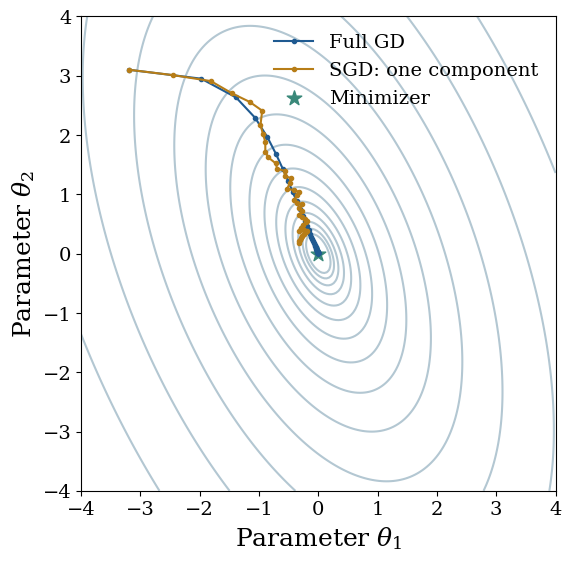

,Batch size b,Exact mean squared gradient error,Measured mean squared gradient error
0,1,0.75375,0.760441
1,4,0.188437,0.194446
2,16,0.0471094,0.0469189
3,64,0.0117773,0.0117042


In [5]:
A = np.array([[3.0, 0.9], [0.9, 1.2]])
centers = np.array([[.25, .25], [.25, -.25], [-.25, .25], [-.25, -.25]])
probe = np.array([.7, -.4])
components = (probe-centers) @ A.T
assert np.allclose(components.mean(axis=0), A@probe)

# Sample indices by I=floor(4U), U uniform on [0,1).
indices = (4*qp.IIDStdUniform(1, seed=SEED).gen_samples(45).ravel()).astype(int)
gd, sgd = [np.array([-3.2, 3.1])], [np.array([-3.2, 3.1])]
for k, i in enumerate(indices):
    gd.append(gd[-1] - .18*A@gd[-1])
    sgd.append(sgd[-1] - .12/np.sqrt(1+k/8)*(A@(sgd[-1]-centers[i])))
gd, sgd = np.array(gd), np.array(sgd)
xx, yy = np.meshgrid(np.linspace(-4, 4, 200), np.linspace(-4, 4, 200))
zz = .5*(A[0,0]*xx**2 + 2*A[0,1]*xx*yy + A[1,1]*yy**2)
fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
ax.contour(xx, yy, zz, levels=np.geomspace(.05, 30, 14), colors='#b3c7d2')
ax.plot(*gd.T, '-o', markersize=3, color=BLUE, label='Full GD')
ax.plot(*sgd.T, '-o', markersize=3, color=GOLD, label='SGD: one component')
ax.scatter([0], [0], marker='*', s=120, color=GREEN, label='Minimizer')
ax.set(xlabel=r'Parameter $\theta_1$', ylabel=r'Parameter $\theta_2$', aspect='equal')
ax.legend(frameon=False)
plt.show()

# The variance identity is exact for independent draws with replacement.
sigma2 = np.mean(np.sum((components-components.mean(axis=0))**2, axis=1))
variance_rows=[]
for b in [1, 4, 16, 64]:
    u = qp.IIDStdUniform(1, seed=SEED+b).gen_samples(4096*b).ravel()
    batch_gradients = components[(4*u).astype(int)].reshape(4096, b, 2).mean(axis=1)
    measured = np.mean(np.sum((batch_gradients-A@probe)**2, axis=1))
    variance_rows.append([b, sigma2/b, measured])
display(pd.DataFrame(variance_rows, columns=['Batch size b', 'Exact mean squared gradient error',
                                            'Measured mean squared gradient error']))

## 4. A solvable noise floor

Take two component losses $\operatorname{loss}_{\pm}(\theta)=(\theta\mp1)^2/2$. Their average has minimizer $\theta_*=0$, and excess loss is $\theta^2/2$. An IID batch mean $\overline a_k$ of $b$ equally likely signs gives
\begin{gather*}
\theta_{k+1}=(1-\eta_k)\theta_k+\eta_k\overline a_k,\qquad
\mathbb E(\theta_{k+1}^2)=(1-\eta_k)^2\mathbb E(\theta_k^2)+\eta_k^2/b.
\end{gather*}
For a constant $0<\eta<2$, the limiting MSE is $\eta/[b(2-\eta)]$. This is a precise example of persistent gradient noise, not a universal noise floor for every finite-sum problem. Component gradients that all vanish at the same minimizer behave differently.

The solid curves solve the exact moment recurrence; the faint curves average independent simulated paths. A larger batch lowers noise at greater work per update. A decaying step lowers the late MSE but eventually makes progress slower. The right panel charges **all $b$ components** in a batch; the horizontal axes answer different questions.

Fixed step, b=1: final exact MSE 0.0526316, simulated MSE 0.0623963, limiting MSE 0.0526316
Fixed step, b=16: final exact MSE 0.00328947, simulated MSE 0.00336516, limiting MSE 0.00328947
Decaying step, b=1: final exact MSE 0.00215889, simulated MSE 0.00225046


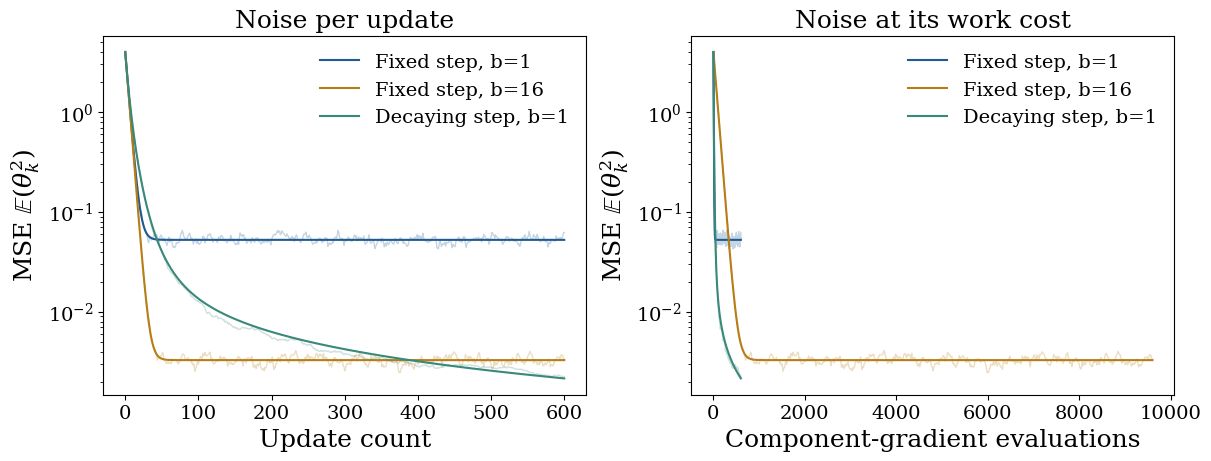

In [6]:
noise_curves=[]
for label, b, decay, color in [('Fixed step, b=1', 1, False, BLUE),
                              ('Fixed step, b=16', 16, False, GOLD),
                              ('Decaying step, b=1', 1, True, GREEN)]:
    u = qp.IIDStdUniform(1, seed=SEED+100+b+int(decay)).gen_samples(
        NOISE_STEPS*NOISE_REPEATS*b).reshape(NOISE_STEPS, NOISE_REPEATS, b)
    means = (2*(u >= .5)-1).mean(axis=2)
    theta = np.full(NOISE_REPEATS, 2.0)
    exact, measured = [4.0], [4.0]
    for k in range(NOISE_STEPS):
        eta = .1/(1+k/20) if decay else .1
        theta = (1-eta)*theta + eta*means[k]
        exact.append((1-eta)**2*exact[-1]+eta**2/b)
        measured.append(np.mean(theta**2))
    if not decay:
        powers = (1-.1)**(2*np.arange(NOISE_STEPS+1))
        closed_form = 4*powers + .1/(b*1.9)*(1-powers)
        assert np.allclose(exact, closed_form), 'Moment recurrence and geometric-series solution disagree'
    noise_curves.append((label,b,np.array(exact),np.array(measured),color))
    print(f'{label}: final exact MSE {exact[-1]:.6g}, simulated MSE {measured[-1]:.6g}'
          + (f', limiting MSE {.1/(b*1.9):.6g}' if not decay else ''))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for label, b, exact, measured, color in noise_curves:
    for ax, abscissa in zip(axes, [np.arange(NOISE_STEPS+1), b*np.arange(NOISE_STEPS+1)]):
        ax.semilogy(abscissa, exact, color=color, label=label)
        ax.semilogy(abscissa, measured, color=color, alpha=.25, linewidth=1)
axes[0].set(xlabel='Update count', ylabel=r'MSE $\mathbb{E}(\theta_k^2)$', title='Noise per update')
axes[1].set(xlabel='Component-gradient evaluations', ylabel=r'MSE $\mathbb{E}(\theta_k^2)$', title='Noise at its work cost')
for ax in axes: ax.legend(frameon=False)
plt.show()

## 5. Logistic regression: large data need not mean high dimension

Each observation is $(\boldsymbol x_i,y_i)$ with $\boldsymbol x_i\in\mathbb R^m$ and $y_i\in\{0,1\}$. Coordinate 1 is an intercept. The remaining coordinates are independent standard normals. With known generating vector $\boldsymbol\beta$, draw
\begin{gather*}
y_i=\boldsymbol1\{U_i<p_i(\boldsymbol\beta)\},\qquad
p_i(\boldsymbol\theta)=\frac{1}{1+\exp(-\boldsymbol x_i^\top\boldsymbol\theta)},\\
\operatorname{loss}_i(\boldsymbol\theta)
=\log(1+\exp(\boldsymbol x_i^\top\boldsymbol\theta))-y_i\boldsymbol x_i^\top\boldsymbol\theta
+\frac\lambda2\|\boldsymbol\theta\|^2,\\
\nabla\operatorname{loss}_i(\boldsymbol\theta)
=(p_i(\boldsymbol\theta)-y_i)\boldsymbol x_i+\lambda\boldsymbol\theta.
\end{gather*}

The full loss is the **average** of these components. We regularize every coefficient, including the intercept, so $\lambda>0$ makes this empirical objective strongly convex. The penalty is included once in each component gradient and therefore once in its average; it must not be divided by the batch size a second time.

`M` controls parameter dimension and `N` controls data size. The known generating vector is **not** the empirical minimizer. A tightly solved L-BFGS reference supplies the empirical target loss. Reference solving and data generation are reported separately and are not competitor runs.

In [7]:
t0 = time.perf_counter()
X = np.column_stack([np.ones(N), qp.Gaussian(qp.IIDStdUniform(M-1, seed=SEED+200)).gen_samples(N)])
beta = np.r_[.3, np.linspace(-1, 1, M-1)/np.sqrt(M-1)*2]
y = (qp.IIDStdUniform(1, seed=SEED+201).gen_samples(N).ravel() < expit(X@beta)).astype(float)
data_seconds = time.perf_counter()-t0

def logistic_loss(theta):
    z = X@theta
    return np.mean(np.logaddexp(0, z)-y*z) + REGULARIZATION*(theta@theta)/2

def logistic_gradient(theta, indices=None):
    xb, yb = (X, y) if indices is None else (X[indices], y[indices])
    return xb.T@(expit(xb@theta)-yb)/len(yb) + REGULARIZATION*theta

# Independent finite differences and explicit component averaging check the model.
probe = np.linspace(-.1, .1, M)
h = 1e-5
numeric = np.array([(logistic_loss(probe+h*np.eye(M)[j])-logistic_loss(probe-h*np.eye(M)[j]))/(2*h)
                    for j in range(M)])
assert np.allclose(logistic_gradient(probe), numeric, atol=1e-8, rtol=1e-5)
all_components = (expit(X@probe)-y)[:,None]*X + REGULARIZATION*probe
assert np.allclose(all_components.mean(axis=0), logistic_gradient(probe))
# logaddexp and expit also work for extreme logits without clipping the objective.
assert np.isfinite(logistic_loss(np.full(M, 1000.)))

# Hessian <= X.T@X/(4N) + lambda I, uniformly in theta.
L_bound = np.linalg.eigvalsh(X.T@X/(4*N))[-1]+REGULARIZATION
t0 = time.perf_counter()
reference = minimize(logistic_loss, np.zeros(M), jac=logistic_gradient, method='L-BFGS-B',
                     options={'gtol': 1e-11, 'ftol': 1e-15, 'maxiter': 2000})
reference_seconds = time.perf_counter()-t0
assert reference.success, reference.message
assert np.linalg.norm(logistic_gradient(reference.x), np.inf) < 1e-7
reference_loss = reference.fun
print(f'N={N:,}, m={M}; data matrix {X.nbytes/2**20:.2f} MiB; labels mean {y.mean():.3f}')
print(f'Data generation {data_seconds:.3f} s; reference solve {reference_seconds:.3f} s')
print(f'Reference loss {reference_loss:.12f}; gradient infinity norm '
      f'{np.linalg.norm(logistic_gradient(reference.x),np.inf):.3g}')
print(f'Full-GD learning rate 1/L = {1/L_bound:.4g}, using a uniform Hessian bound')

N=16,384, m=20; data matrix 2.50 MiB; labels mean 0.555
Data generation 0.007 s; reference solve 0.006 s
Reference loss 0.570684340602; gradient infinity norm 1.78e-11
Full-GD learning rate 1/L = 3.504, using a uniform Hessian bound


## 6. Compare gradient work and elapsed time separately

Every run uses exactly `N * BUDGET_PASSES` component-gradient contributions. Dividing this work by $N$ gives **equivalent data passes**. For SGD these are draws with replacement, not epochs visiting every observation exactly once. The initial iterate is recorded; logarithmic plots show the positive-work/time checkpoints. The loss-gap plotting floor is $10^{-12}$; the tables retain the computed gaps.

- **Full GD:** step $1/L$, where $L$ bounds the logistic Hessian
- **Single-observation SGD:** $\eta_k=0.3/(1+w_k/(0.25N))$
- **Mini-batch SGD:** step 0.3, or the same decaying schedule

Here $w_k$ is component work before update $k$, so decay is tied to **data access**, not an arbitrary update count. These are declared teaching choices, not an optimal hyperparameter search.

Each stochastic run samples fresh IID indices. Index generation, array selection, arithmetic, snapshot storage, and update bookkeeping are inside its optimization timer. An index buffer generates 4096 uniform draws at a time, including unused draws in the final buffer. No full loss is evaluated inside these timers. We save at most about 45 parameter snapshots and evaluate **every full loss afterward**, with diagnostic seconds reported separately. Otherwise frequent $N$-row loss checks could erase the benefit we are trying to measure.

Each method gets a short untimed warmup, then `TIMING_REPEATS` complete measured runs. Timing curves show medians at common work checkpoints; bands show the observed range, not confidence intervals. Data/reference setup is shared and excluded from the optimization timer. Curves are machine-specific: vectorized full gradients may beat Python-level SGD even when the latter uses fewer rows early.

In [8]:
class IIDIndices:
    def __init__(self, seed):
        self.sampler = qp.IIDStdUniform(1, seed=seed)
        self.buffer = np.empty(0, dtype=int)
        self.cursor = 0
    def take(self, size):
        if self.cursor+size > len(self.buffer):
            self.buffer = (N*self.sampler.gen_samples(max(4096,size)).ravel()).astype(int)
            self.cursor = 0
        result = self.buffer[self.cursor:self.cursor+size]
        self.cursor += size
        return result

METHODS = [
    ('Full GD', None, False, BLUE),
    ('SGD, b=1, decay', 1, True, RED),
    (f'Mini-batch b={BATCH_SIZE}, fixed', BATCH_SIZE, False, GOLD),
    (f'Mini-batch b={BATCH_SIZE}, decay', BATCH_SIZE, True, GREEN),
]

def optimize(method, seed, budget):
    name, b, decay, color = method
    size = N if b is None else b
    updates = int(np.ceil(budget/size))
    checkpoints = set(np.unique(np.geomspace(1, updates, min(45,updates)).astype(int)))
    theta = np.zeros(M)
    works, seconds, snapshots = [0], [0.0], [theta.copy()]
    started = time.perf_counter()
    sampler = IIDIndices(seed) if b is not None else None
    work = 0
    for k in range(1, updates+1):
        used = min(size, budget-work)
        if b is None:
            # Full runs have an integer number of complete N-row gradients.
            assert used == N
            g = logistic_gradient(theta)
            eta = 1/L_bound
        else:
            g = logistic_gradient(theta, sampler.take(used))
            eta = .3/(1+work/(.25*N)) if decay else .3
        theta -= eta*g
        work += used
        if k in checkpoints:
            works.append(work)
            snapshots.append(theta.copy())
            seconds.append(time.perf_counter()-started)
    elapsed = time.perf_counter()-started
    # Stop the timer before evaluating any full-loss diagnostics.
    seconds[-1] = elapsed
    diagnostic_start = time.perf_counter()
    losses = np.array([logistic_loss(x) for x in snapshots])
    diagnostic_seconds = time.perf_counter()-diagnostic_start
    assert work == budget and np.all(np.isfinite(losses))
    assert np.all(losses >= reference_loss-1e-10), 'Reference loss is not a valid numerical lower target'
    return dict(work=np.array(works), seconds=np.array(seconds), loss=losses,
                gap=np.maximum(losses-reference_loss,0), elapsed=elapsed,
                diagnostics=diagnostic_seconds, updates=updates)

# Warm up exactly the same gradient/selection paths; use independent seeds for measured runs.
for method in METHODS:
    optimize(method, SEED+300, N if method[1] is None else min(N,20*method[1]))
results={}
for j, method in enumerate(METHODS):
    results[method[0]] = [optimize(method, SEED+400+100*j+r, N*BUDGET_PASSES)
                          for r in range(TIMING_REPEATS)]
print('All optimizer runs used the same component-gradient budget; diagnostics were evaluated afterward.')

All optimizer runs used the same component-gradient budget; diagnostics were evaluated afterward.


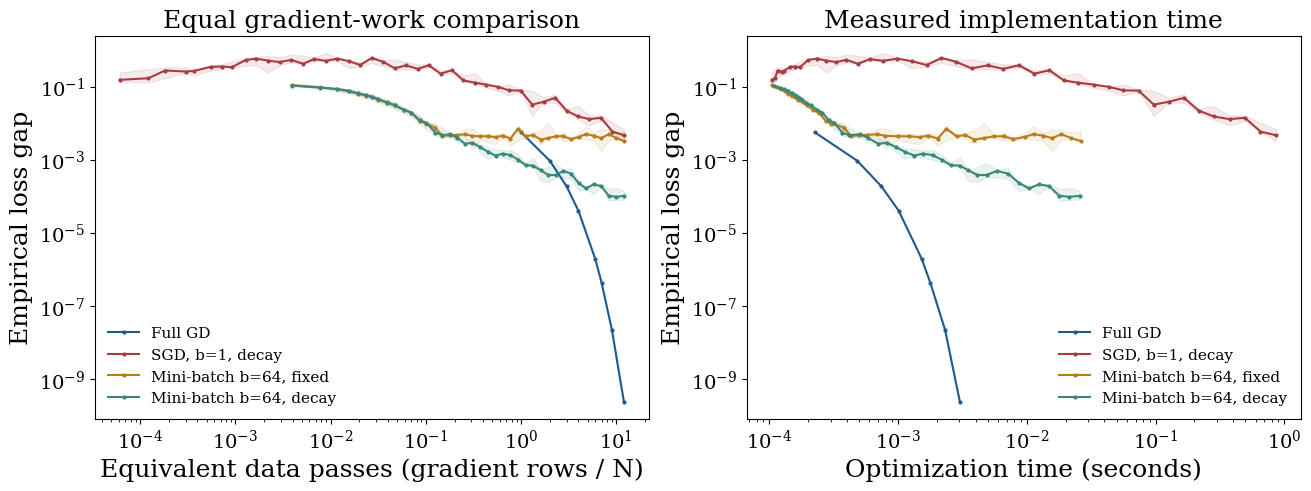

,Method,Updates,Gradient rows,Optimization seconds (median),Diagnostic seconds (median),Final loss gap (median)
0,Full GD,12,196608,0.00301917,0.00339033,2.48157e-10
1,"SGD, b=1, decay",196608,196608,0.861809,0.0165715,0.00469175
2,"Mini-batch b=64, fixed",3072,196608,0.0261903,0.0150932,0.00324939
3,"Mini-batch b=64, decay",3072,196608,0.025736,0.0149394,0.000103668


In this run, Full GD used the least optimization time: 0.003019 s, with final loss gap 2.48e-10. Read time and accuracy together.


,Method,Requested loss gap,Runs reaching target,First recorded seconds (median of successes)
0,Full GD,0.01,3/3,0.000226042
1,Full GD,0.0001,3/3,0.001012
2,Full GD,1e-06,3/3,0.00178067
3,"SGD, b=1, decay",0.01,3/3,0.63687
4,"SGD, b=1, decay",0.0001,0/3,NaN
5,"SGD, b=1, decay",1e-06,0/3,NaN
6,"Mini-batch b=64, fixed",0.01,3/3,0.000304084
7,"Mini-batch b=64, fixed",0.0001,0/3,NaN
8,"Mini-batch b=64, fixed",1e-06,0/3,NaN
9,"Mini-batch b=64, decay",0.01,3/3,0.0003685


NaN means no recorded attainment within the budget; success-only medians are not comparable without reading the success count. Checkpoint spacing limits the time resolution.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
rows=[]
for name, b, decay, color in METHODS:
    runs = results[name]
    gaps = np.array([r['gap'] for r in runs])
    median_gap = np.maximum(np.median(gaps,axis=0), 1e-12)
    med_seconds = np.median([r['seconds'] for r in runs],axis=0)
    work = runs[0]['work']/N
    for ax, x in [(axes[0],work), (axes[1],med_seconds)]:
        ax.plot(x[1:], median_gap[1:], color=color, marker='.', markersize=4, label=name)
        ax.fill_between(x[1:], np.maximum(gaps.min(axis=0)[1:],1e-12),
                         np.maximum(gaps.max(axis=0)[1:],1e-12), color=color, alpha=.1)
    rows.append([name, runs[0]['updates'], int(runs[0]['work'][-1]),
                 np.median([r['elapsed'] for r in runs]),
                 np.median([r['diagnostics'] for r in runs]), np.median(gaps[:,-1])])
axes[0].set(xlabel='Equivalent data passes (gradient rows / N)', title='Equal gradient-work comparison')
axes[1].set(xlabel='Optimization time (seconds)', title='Measured implementation time')
for ax in axes:
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_ylabel('Empirical loss gap')
    ax.legend(frameon=False,fontsize=11)
plt.show()
summary=pd.DataFrame(rows,columns=['Method','Updates','Gradient rows','Optimization seconds (median)',
                                  'Diagnostic seconds (median)','Final loss gap (median)'])
display(summary)
best = summary.loc[summary['Optimization seconds (median)'].idxmin()]
print(f"In this run, {best['Method']} used the least optimization time: "
      f"{best['Optimization seconds (median)']:.4g} s, with final loss gap "
      f"{best['Final loss gap (median)']:.3g}. Read time and accuracy together.")

# First recorded attainment, not an interpolated or assumed crossing.
attainments=[]
for name, _, _, _ in METHODS:
    for target in [1e-2,1e-4,1e-6]:
        hits=[np.flatnonzero(r['gap']<=target) for r in results[name]]
        times=[r['seconds'][h[0]] for r,h in zip(results[name],hits) if len(h)]
        attainments.append([name,target,f'{len(times)}/{TIMING_REPEATS}',
                             np.median(times) if times else np.nan])
display(pd.DataFrame(attainments,columns=['Method','Requested loss gap','Runs reaching target',
                                          'First recorded seconds (median of successes)']))
print('NaN means no recorded attainment within the budget; success-only medians are not comparable '
      'without reading the success count. Checkpoint spacing limits the time resolution.')

## 7. What these experiments establish

The Rosenbrock experiment isolates **geometry**. Its narrow valley remains difficult for GD with a line search. BFGS uses curvature information to improve its route. A high parameter count would not remove that issue.

The quadratic experiments isolate **sampling noise**. Mini-batch gradient MSE decreases as $1/b$ for fresh independent component draws. With nonvanishing component noise, a fixed step can leave a noise floor. A smaller or decreasing step improves fine accuracy at the cost of slower progress.

The logistic experiment isolates **data-access cost**. Compare the left panel before the first complete data pass, then near the final requested loss gap. Read the measured time panel separately: row counts omit Python overhead, memory traffic, vectorization, and library threading. No method is declared universally faster, and this CPU implementation predicts no GPU speedup. Full-gradient and curvature-aware methods can be excellent when full gradients are affordable or high precision is needed.

A dense Hessian uses $O(m^2)$ storage, with an $O(m^3)$ naive dense solve. **L-BFGS**, sparse structure, and Hessian-vector methods can avoid those costs. Reverse-mode automatic differentiation, also called **adjoint-mode differentiation** or a **discrete adjoint method**, can compute the whole gradient at cost comparable to a few loss evaluations; large $m$ does not imply $m$ finite-difference evaluations. In neural networks this is called **backpropagation**. Momentum and Adam are additional ways to modify first-order updates, not general cures for conditioning or nonconvexity.

Optimization loss and prediction error are different. This notebook measures an empirical optimization objective; it does not test generalization or prove a global-minimum result for neural networks.

### Try next

1. Set `M=2` and increase `N`. Does the data-access advantage need high dimension?
2. Hold `N` fixed and increase `M`. Which storage and arithmetic costs increase? Does this necessarily worsen conditioning?
3. Change `BATCH_SIZE` and the declared step sizes. Compare early progress with attainment of a gap of $10^{-6}$. Changing only the plotted update count is not an equal-work comparison.
4. In the scalar recurrence, predict the noise floor for $b=4$ and $\eta=0.05$ before running it.

### References

- [Bottou, Curtis, and Nocedal (2018), Optimization Methods for Large-Scale Machine Learning](https://arxiv.org/abs/1606.04838), especially §§3–7
- [SciPy optimization tutorial](https://docs.scipy.org/doc/scipy/tutorial/optimize.html), Rosenbrock, BFGS, Newton and trust-region examples
- [Levitt, The adjoint trick](https://www.imo.universite-paris-saclay.fr/~antoine.levitt/blog/adjoint/), reverse-mode AD, adjoint methods, and backpropagation

In [10]:
elapsed = time.perf_counter() - NOTEBOOK_START_TIME
minutes, seconds = divmod(elapsed, 60)
print(f'Total execution time for this notebook is {int(minutes)} min {seconds:.1f} sec.')

Total execution time for this notebook is 0 min 5.9 sec.
